In [1]:
import os
import numpy as np
import pandas as pd
from collections import defaultdict
from tqdm import trange, tqdm

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.cluster import KMeans


import Orange
from orangecontrib.spectroscopy import data
from orangecontrib.spectroscopy.data import getx
from Orange.data.io import FileFormat
#import Orange.data.io.FileFormat.read_spectra as read_spectra

In [2]:
def read_spectra(self):
        channels = self.get_channels()

        for c, label in channels.items():
            if label.decode("utf-8") == self.sheet:
                self.data_signal = c
                break
        else:
            self.data_signal = list(channels.keys())[0]

        import h5py
        hdf5_file = h5py.File(self.filename,'r')
        keys = list(hdf5_file.keys())

        hyperspectra = False
        intensities = []
        wavenumbers = []
        x_locs = []
        y_locs = []

        # load measurements
        for meas_name in filter(lambda s: s.startswith('Measurement'), keys):
            hdf5_meas = hdf5_file[meas_name]

            meas_keys = list(hdf5_meas.keys())
            meas_attrs = hdf5_meas.attrs

            # check if this measurement contains the selected data channel
            selected_signal = False
            for chan_name in filter(lambda s: s.startswith('Channel'), meas_keys):
                hdf5_chan = hdf5_meas[chan_name]
                if hdf5_chan.attrs.keys().__contains__('DataSignal') and hdf5_chan.attrs['DataSignal'] == self.data_signal:
                    selected_signal = True
                    break
            if not selected_signal:
                continue

            # build range arrays
            spec_vals = []
            try:
                if meas_attrs.keys().__contains__('RangeWavenumberStart'):
                    wn_start = meas_attrs['RangeWavenumberStart'][0]
                    wn_end = meas_attrs['RangeWavenumberEnd'][0]
                    wn_points = meas_attrs['RangeWavenumberPoints'][0]
                    spec_vals = np.linspace(wn_start, wn_end, wn_points)
            except:
                raise IOError("Error reading wavenumber range from " + self.filename)

            pos_vals = []
            try:
                if meas_attrs.keys().__contains__('RangeXStart'):
                    x_start = meas_attrs['RangeXStart'][0]
                    x_points = meas_attrs['RangeXPoints'][0]
                    x_incr = meas_attrs['RangeXIncrement'][0]
                    x_end = x_start + x_incr * (x_points - 1)
                    x_min = min(x_start, x_end)
                    if meas_attrs.keys().__contains__('RangeYStart'):
                        y_start = meas_attrs['RangeYStart'][0]
                        y_points = meas_attrs['RangeYPoints'][0]
                        y_incr = meas_attrs['RangeYIncrement'][0]
                        y_end = y_start + y_incr * (y_points - 1)
                        y_min = min(y_start, y_end)

                        # construct the positions array
                        for iY in range(int(y_points)):
                            y = y_min + iY * abs(y_incr)
                            for iX in range(int(x_points)):
                                x = x_min + iX * abs(x_incr)
                                pos_vals.append([x, y])
                        pos_vals = np.array(pos_vals)
                else:
                    pos_vals = np.array([1])
            except:
                raise IOError("Error reading position data from " + self.filename)

            hyperspectra = pos_vals.shape[0] > 1

            # ignore backgrounds and unchecked data
            if not hyperspectra:
                if meas_attrs.keys().__contains__('IsBackground') and meas_attrs['IsBackground'][0]:
                    continue
                if meas_attrs.keys().__contains__('Checked') and not meas_attrs['Checked'][0]:
                    continue

            if len(wavenumbers) == 0:
                wavenumbers = spec_vals

            if hyperspectra:
                x_len = meas_attrs['RangeXPoints'][0]
                y_len = meas_attrs['RangeYPoints'][0]
                x_locs = pos_vals[:x_len,0]
                y_indices = np.round(np.linspace(0, pos_vals.shape[0] - 1, y_len)).astype(int)
                y_locs = pos_vals[y_indices,1]
            else:
                x_locs.append(meas_attrs['LocationX'][0])
                y_locs.append(meas_attrs['LocationY'][0])

            # load channels
            for chan_name in filter(lambda s: s.startswith('Channel'), meas_keys):
                hdf5_chan = hdf5_meas[chan_name]
                chan_attrs = hdf5_chan.attrs

                signal = chan_attrs['DataSignal']
                if signal != self.data_signal:
                    continue

                data = hdf5_chan['Raw_Data']
                if hyperspectra:
                    rows = meas_attrs['RangeYPoints'][0]
                    cols = meas_attrs['RangeXPoints'][0]
                    intensities = np.reshape(data, (rows,cols,data.shape[1])) # organized rows, columns, wavelengths
                    break
                else:
                    intensities.append(data[0,:])

        #intensities = np.array(intensities)
        #features = np.array(wavenumbers)
        intensities = intensities
        features = np.array(wavenumbers)
        x_locs = np.array(x_locs).flatten()
        y_locs = np.array(y_locs).flatten()
        if hyperspectra:
            return _spectra_from_image(intensities, features, x_locs, y_locs)
        else:
            spectra = intensities

            # locations
            x_loc = y_loc = np.arange(len(spectra))
            metas = np.array([x_locs[x_loc], y_locs[y_loc]]).T

            domain = Orange.data.Domain([], None,
                                        metas=[Orange.data.ContinuousVariable.make("map_x"),
                                               Orange.data.ContinuousVariable.make("map_y")]
                                        )
            data = Orange.data.Table.from_numpy(domain, X=np.zeros((len(spectra), 0)),
                                                metas=np.asarray(metas, dtype=object))
            return features, spectra, data

In [3]:
#Orange.data.Table('MEC_02_115_CR_N_01_20240319.ptir')

In [4]:
path = '../MEC_02_115/Raw Data/'
dirs = os.listdir(path)
dirs

['CR_N_01', 'FB_N_02', 'KC_N_01', 'CR_N_02', 'FB_N_01', 'MF_N_01', 'KC_N_02']

In [5]:
files_list = []
for d in dirs:
    files = os.listdir(path + d)
    files_list = files_list + [d+'/'+f for f in files if f[-5:] == '.ptir']
    #print([f for f in files if f[-5:] == '.ptir'])

In [6]:
files_codes = pd.merge(pd.DataFrame({'file_name':files_list,
                                     'key':[str(x[:2]) for x in files_list],
                                     'run':[str(x[5:7]) for x in files_list],
                                     'day':[str(x[-9:-5]) for x in files_list],}),
                       pd.DataFrame({'key':np.unique([str(x[:2]) for x in files_list]),
                                     'brand':['CR', 'FB', 'KC', 'MF']}))
files_codes = files_codes.set_index('file_name')
files_codes

,key,run,day,brand
file_name,,,,
CR_N_01/MEC_02_115_CR_N_01_20240319.ptir,CR,01,0319,CR
CR_N_02/MEC_02_115_CR_N_02_20240326.ptir,CR,02,0326,CR
CR_N_02/MEC_02_115_CR_N_02_20240319.ptir,CR,02,0319,CR
FB_N_02/MEC_02_115_FB_N_02_20240404.ptir,FB,02,0404,FB
FB_N_01/MEC_02_115_FB_N_01_20240328.ptir,FB,01,0328,FB
KC_N_01/MEC_02_115_KC_N_01_20240321.ptir,KC,01,0321,KC
KC_N_02/MEC_02_115_KC_N_02_20240326.ptir,KC,02,0326,KC
KC_N_02/MEC_02_115_KC_N_02_20240328.ptir,KC,02,0328,KC
MF_N_01/MEC_02_115_MF_N_01_20240405.ptir,MF,01,0405,MF


In [7]:
spectra_list = []

for f in files_list:
    absolute_filename = FileFormat.locate(path + f)
    #absolute_filename = FileFormat.locate('MEC_02_115_CR_N_01_20240319.ptir')
    reader = FileFormat.get_reader(absolute_filename)
    sheet = 'OPTIR (mV)'
    reader.select_sheet(sheet)
    spectra = read_spectra(reader)

    spectra_data = pd.DataFrame(spectra[1])
    coords = spectra[2].to_pandas_dfs()[2].reset_index(drop=True)
    spectra_data = spectra_data.reset_index(drop=True)
    spectra_data.columns = spectra[0]
    #spectra_data_bg = spectra_data.loc[:, ~np.isnan(spectra_data.iloc[0,:])]
    #if max(spectra_data.columns) < 3004.0:
    #    spectra_data[3004] = 0
    
    spectra_data['id'] = [files_codes.loc[f, 'brand'] + '_' + 
                          files_codes.loc[f, 'run'] + '_' + 
                          files_codes.loc[f, 'day'] + '_' + 
                          str(i + 1) for i in range(spectra_data.shape[0])]
    spectra_data = pd.concat([spectra_data, coords],axis=1)
    #spectra_data['id'] = [f+ '_' + str(i) for i in range(spectra_data.shape[0])]
    #spectra_data['run_file_name'] = f
    spectra_data['brand'] = files_codes.loc[f, 'brand']
    spectra_data['run'] = files_codes.loc[f, 'run']
    spectra_data['day'] = files_codes.loc[f, 'day']
    #spectra_data['sample_id'] = np.arange(spectra_data.shape[0]) + 1
    spectra_list.append(spectra_data)    

spectra_ir_df = pd.concat(spectra_list)
spectra_ir_df

,948.0,950.0,952.0,954.0,956.0,958.0,960.0,962.0,964.0,966.0,...,2996.0,2998.0,3000.0,3002.0,id,map_x,map_y,brand,run,day
0,-3.305811,-2.244836,-1.808550,-1.441703,-1.005475,-0.666216,-0.634051,-0.344357,-0.414275,-0.538892,...,-1.364635,-1.015415,-3.303930,-3.520125,CR_01_0319_1,-2968.649902,-2010.150024,CR,01,0319
1,1.589247,0.587879,-0.132626,0.832453,0.197233,0.157895,-0.055195,-0.236536,-0.073942,0.058277,...,1.244847,0.068627,-0.406120,-1.435895,CR_01_0319_2,-2970.300049,-2006.150024,CR,01,0319
2,1.536974,-0.241123,0.317267,-0.392871,-0.077576,0.261614,0.017024,0.120983,-0.054634,-0.082392,...,-0.452987,-0.312717,0.512639,0.211609,CR_01_0319_3,-2960.850098,-2002.0,CR,01,0319
3,0.429390,-0.283086,-0.152739,0.169562,0.283499,-0.085923,-0.137004,-0.470308,-0.018342,0.125664,...,-1.260288,-1.706861,0.463105,-0.235947,CR_01_0319_4,-2946.300049,-1993.800049,CR,01,0319
4,-0.851665,0.260913,-0.934513,-0.355387,-0.081696,-0.180108,-0.279048,-0.394081,-0.266154,0.385534,...,-0.206879,0.536171,-0.477935,-0.128079,CR_01_0319_5,-2935.0,-1992.449951,CR,01,0319
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
27,-0.060284,0.557875,0.459524,0.306358,0.177851,0.499784,0.440978,-0.025045,-0.020101,-0.063076,...,0.213426,0.801208,0.832383,0.793913,KC_02_0328_28,-4543.5,-1759.75,KC,02,0328
28,-0.224498,-1.765926,-1.666877,-0.438259,0.020466,-0.033487,-0.052281,-0.242959,-0.138028,-0.317322,...,-0.163860,0.123000,-1.466878,-1.311235,KC_02_0328_29,-4501.899902,-1758.099976,KC,02,0328
29,-1.435758,-1.585154,-1.323444,-0.828181,-1.129116,-0.718950,-0.295729,0.029341,-0.312351,-0.225063,...,-1.668260,-2.328258,-2.125748,-1.402201,KC_02_0328_30,-4510.850098,-1747.099976,KC,02,0328
30,0.572048,0.026594,0.111077,0.057758,-0.151336,0.168770,0.375415,0.252623,0.012098,0.329679,...,13.735632,10.824211,9.217921,8.421560,KC_02_0328_31,-4511.100098,-1743.050049,KC,02,0328


In [8]:
spectra_list = []

for f in files_list:
    absolute_filename = FileFormat.locate(path + f)
    #absolute_filename = FileFormat.locate('MEC_02_115_CR_N_01_20240319.ptir')
    reader = FileFormat.get_reader(absolute_filename)
    sheet = 'Raman Intensity'
    reader.select_sheet(sheet)
    spectra = read_spectra(reader)

    spectra_data = pd.DataFrame(spectra[1])
    coords = spectra[2].to_pandas_dfs()[2].reset_index(drop=True)
    spectra_data = spectra_data.reset_index(drop=True)
    spectra_data.columns = spectra[0]
    #spectra_data_bg = spectra_data.loc[:, ~np.isnan(spectra_data.iloc[0,:])]
    #if max(spectra_data.columns) < 3004.0:
    #    spectra_data[3004] = 0
    
    spectra_data['id'] = [files_codes.loc[f, 'brand'] + '_' + 
                          files_codes.loc[f, 'run'] + '_' + 
                          files_codes.loc[f, 'day'] + '_' + 
                          str(i + 1) for i in range(spectra_data.shape[0])]
    spectra_data = pd.concat([spectra_data, coords],axis=1)
    #spectra_data['id'] = [f+ '_' + str(i) for i in range(spectra_data.shape[0])]
    #spectra_data['run_file_name'] = f
    spectra_data['brand'] = files_codes.loc[f, 'brand']
    spectra_data['run'] = files_codes.loc[f, 'run']
    spectra_data['day'] = files_codes.loc[f, 'day']
    #spectra_data['sample_id'] = np.arange(spectra_data.shape[0]) + 1
    spectra_list.append(spectra_data)    

spectra_raman_df = pd.concat(spectra_list)
spectra_raman_df

,326.1221507938171,329.5937686606638,333.0653865275105,336.53700439435715,340.00862226120387,343.4802401280505,346.95185799489724,350.4234758617439,353.8950937285906,357.36671159543727,...,3867.172374977435,3870.643992844282,3874.1156107111287,3877.587228577975,id,map_x,map_y,brand,run,day
0,1794.666626,1752.576660,1763.867920,1770.988159,1760.301270,1780.839722,1821.787842,1851.077026,1902.091431,1986.960083,...,1915.923950,1903.408569,1907.495483,1935.333374,CR_01_0319_1,-2968.649902,-2010.150024,CR,01,0319
1,1746.000000,1738.108154,1738.719604,1728.901245,1723.339966,1790.221680,1800.465454,1819.483765,1862.178711,1923.559814,...,1822.359131,1809.253662,1817.538452,1836.000000,CR_01_0319_2,-2970.300049,-2006.150024,CR,01,0319
2,1693.333374,1678.601807,1690.596191,1700.998657,1703.744873,1724.809937,1767.777222,1817.423218,1859.007324,1889.279053,...,1822.127808,1831.702393,1844.551758,1852.000000,CR_01_0319_3,-2960.850098,-2002.0,CR,01,0319
3,1682.666626,1682.666626,1683.055176,1687.839355,1699.855225,1721.446899,1756.486328,1792.688843,1846.801758,1919.419434,...,1894.718506,1867.576660,1906.510620,1948.666626,CR_01_0319_4,-2946.300049,-1993.800049,CR,01,0319
4,1676.666626,1625.106323,1642.804077,1657.573120,1658.452637,1724.281128,1722.777832,1760.537964,1828.128784,1900.987183,...,1804.616333,1792.200928,1803.889282,1831.333374,CR_01_0319_5,-2935.0,-1992.449951,CR,01,0319
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
27,1690.000000,1691.578369,1707.541016,1733.436035,1761.970337,1780.928955,1803.883301,1838.169067,1884.668823,1948.736694,...,1985.039673,1946.911865,1915.723267,1953.333374,KC_02_0328_28,-4543.5,-1759.75,KC,02,0328
28,1645.000000,1689.983765,1721.037842,1735.167358,1739.970337,1758.928955,1811.226807,1865.521118,1910.321899,1949.599609,...,2002.001099,2001.886353,1985.557129,2046.000000,KC_02_0328_29,-4501.899902,-1758.099976,KC,02,0328
29,1812.666626,1845.812622,1844.176392,1858.945923,1900.080688,1919.565796,1945.534058,1995.863770,2034.421631,2052.350830,...,2281.691895,2312.100586,2284.014648,2202.000000,KC_02_0328_30,-4510.850098,-1747.099976,KC,02,0328
30,2240.000000,2258.940430,2259.337646,2271.395264,2306.098877,2349.545654,2372.142578,2382.757080,2408.785156,2467.679443,...,2814.306396,2856.691895,2870.166016,2899.000000,KC_02_0328_31,-4511.100098,-1743.050049,KC,02,0328


In [9]:
spectra_ir_df.to_csv('data_ir.csv')
spectra_raman_df.to_csv('data_raman.csv')

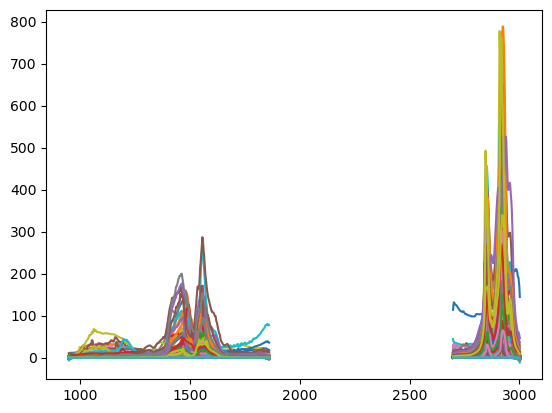

In [14]:
_ = plt.plot(spectra_ir_df.iloc[:,:-6].T)

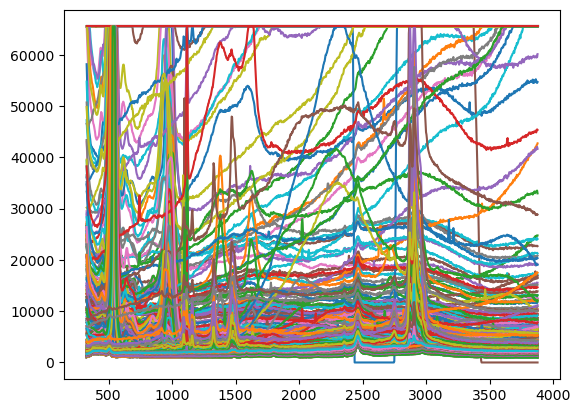

In [15]:
_ = plt.plot(spectra_raman_df.iloc[:,:-6].T)